In [46]:
# ep_vs_bp.py

import numpy as np
import torch
import matplotlib.pyplot as plt


# =============================================================================
# DATA GENERATION
# =============================================================================

def generate_linearly_separable_data(n_samples=100, seed=42):
    """
    Generate simple linearly separable 2D dataset

    Parameters:
    -----------
    n_samples : int
        Total number of samples (split evenly between classes)
    seed : int
        Random seed for reproducibility

    Returns:
    --------
    X : torch.Tensor, shape (n_samples, 2)
        Input features
    y : torch.Tensor, shape (n_samples, 1)
        Binary labels (0 or 1)
    """
    np.random.seed(seed)

    # Class 0: points around (-1, -1)
    x0 = np.random.randn(n_samples // 2, 2) * 1 + np.array([-1, -1])
    y0 = np.zeros(n_samples // 2)

    # Class 1: points around (1, 1)
    x1 = np.random.randn(n_samples // 2, 2) * 1 + np.array([1, 1])
    y1 = np.ones(n_samples // 2)

    X = np.vstack([x0, x1]).astype(np.float32)
    y = np.hstack([y0, y1]).astype(np.float32)

    # Shuffle
    idx = np.random.permutation(n_samples)
    return torch.tensor(X[idx]), torch.tensor(y[idx]).unsqueeze(1)


# =============================================================================
# MODEL
# =============================================================================

class SimplePerceptron:
    """
    Single layer perceptron with 2 weights + 1 bias
    Output: sigmoid(w1*x1 + w2*x2 + b)

    Parameters:
    -----------
    seed : int, optional
        Random seed for weight initialization
    """

    def __init__(self, seed=None):
        if seed is not None:
            torch.manual_seed(seed)
        # Use nn.Parameter-like behavior by wrapping in a list for proper gradient tracking
        self.w = torch.randn(2, 1) * 0.1
        self.w.requires_grad_(True)
        self.b = torch.zeros(1)
        self.b.requires_grad_(True)

    def forward(self, x):
        """Forward pass"""
        return torch.sigmoid(torch.mm(x, self.w) + self.b)

    def energy(self, x, s):
        """
        Energy function for equilibrium propagation

        Parameters:
        -----------
        x : torch.Tensor
            Input data
        s : torch.Tensor
            State variable (neuron activation)
        """
        pre_activation = torch.mm(x, self.w) + self.b
        target_s = torch.sigmoid(pre_activation)
        return 0.5 * torch.sum((s - target_s) ** 2, dim=1)

    def cost(self, s, y):
        """Squared error cost"""
        return 0.5 * torch.sum((s - y) ** 2, dim=1)

    def get_weights(self):
        """Return current weights as numpy arrays"""
        return {
            'w': self.w.detach().numpy().flatten().copy(),
            'b': self.b.detach().numpy().copy()
        }

    def zero_grad(self):
        """Zero out gradients"""
        if self.w.grad is not None:
            self.w.grad.zero_()
        if self.b.grad is not None:
            self.b.grad.zero_()

    def __repr__(self):
        w = self.w.detach().numpy().flatten()
        b = self.b.item()
        return f"SimplePerceptron(w=[{w[0]:.4f}, {w[1]:.4f}], b={b:.4f})"


# =============================================================================
# TRAINING FUNCTIONS
# =============================================================================

def train_backprop(model, X, y, num_epochs=100, lr=0.1, verbose=True, log_every=10):
    """
    Train using standard backpropagation

    Parameters:
    -----------
    model : SimplePerceptron
        The model to train
    X : torch.Tensor
        Input data
    y : torch.Tensor
        Labels
    num_epochs : int
        Number of training epochs
    lr : float
        Learning rate
    verbose : bool
        Whether to print progress
    log_every : int
        Print every N epochs

    Returns:
    --------
    history : dict
        Dictionary containing 'losses', 'accuracies', 'weights' over training
    """
    history = {
        'losses': [],
        'accuracies': [],
        'weights': []
    }
    if X != torch.Tensor:
        X = torch.tensor(X)
    if y != torch.Tensor:
        y = torch.tensor(y)
    for epoch in range(num_epochs):
        # Zero gradients
        model.zero_grad()

        # Forward pass
        output = model.forward(X)

        # Compute loss (MSE)
        loss = 0.5 * torch.mean((output - y) ** 2)

        # Backward pass
        loss.backward()

        # Update weights
        with torch.no_grad():
            model.w -= lr * model.w.grad
            model.b -= lr * model.b.grad

        # Track metrics
        with torch.no_grad():
            output_eval = model.forward(X)
            predictions = (output_eval > 0.5).float()
            accuracy = (predictions == y).float().mean().item()

        history['losses'].append(loss.item())
        history['accuracies'].append(accuracy)
        history['weights'].append(model.get_weights())

        if verbose and epoch % log_every == 0:
            print(f"BP Epoch {epoch}: Loss = {loss.item():.4f}, Accuracy = {accuracy:.2%}")

    return history


def train_equilibrium_prop(model, X, y, num_epochs=100, lr=0.1, beta=0.5,
                           num_iterations=20, state_lr=0.5, verbose=True, log_every=10):
    """
    Train using Equilibrium Propagation

    Parameters:
    -----------
    model : SimplePerceptron
        The model to train
    X : torch.Tensor
        Input data
    y : torch.Tensor
        Labels
    num_epochs : int
        Number of training epochs
    lr : float
        Learning rate for weights
    beta : float
        Nudging factor
    num_iterations : int
        Number of iterations for energy minimization
    state_lr : float
        Learning rate for state updates during energy minimization
    verbose : bool
        Whether to print progress
    log_every : int
        Print every N epochs

    Returns:
    --------
    history : dict
        Dictionary containing 'losses', 'accuracies', 'weights' over training
    """
    history = {
        'losses': [],
        'accuracies': [],
        'weights': [],
        's_free': [],
        's_nudged': []
    }

    for epoch in range(num_epochs):
        # Initialize state variable from forward pass
        with torch.no_grad():
            s_init = model.forward(X).clone()

        # === FREE PHASE ===
        s_free = s_init.clone().detach().requires_grad_(True)

        for _ in range(num_iterations):
            if s_free.grad is not None:
                s_free.grad.zero_()
            energy = model.energy(X, s_free).mean()
            energy.backward()
            with torch.no_grad():
                s_free -= state_lr * s_free.grad
            s_free = s_free.detach().requires_grad_(True)

        s_free_final = s_free.detach().clone()

        # === NUDGED PHASE ===
        s_nudged = s_free_final.clone().detach().requires_grad_(True)

        for _ in range(num_iterations):
            if s_nudged.grad is not None:
                s_nudged.grad.zero_()
            energy = model.energy(X, s_nudged).mean()
            cost = model.cost(s_nudged, y).mean()
            total = energy + beta * cost
            total.backward()
            with torch.no_grad():
                s_nudged -= state_lr * s_nudged.grad
            s_nudged = s_nudged.detach().requires_grad_(True)

        s_nudged_final = s_nudged.detach().clone()

        # === WEIGHT UPDATE ===
        # Compute gradients at free equilibrium
        model.zero_grad()
        s_free_for_grad = s_free_final.clone().detach()
        energy_free = model.energy(X, s_free_for_grad).mean()
        energy_free.backward()
        grad_w_free = model.w.grad.clone()
        grad_b_free = model.b.grad.clone()

        # Compute gradients at nudged equilibrium
        model.zero_grad()
        s_nudged_for_grad = s_nudged_final.clone().detach()
        energy_nudged = model.energy(X, s_nudged_for_grad).mean()
        cost_nudged = model.cost(s_nudged_for_grad, y).mean()
        total_nudged = energy_nudged + beta * cost_nudged
        total_nudged.backward()
        grad_w_nudged = model.w.grad.clone()
        grad_b_nudged = model.b.grad.clone()

        # EP weight update
        with torch.no_grad():
            model.w -= (lr / beta) * (grad_w_nudged - grad_w_free)
            model.b -= (lr / beta) * (grad_b_nudged - grad_b_free)

        # Track metrics
        with torch.no_grad():
            output = model.forward(X)
            loss = 0.5 * torch.mean((output - y) ** 2).item()
            predictions = (output > 0.5).float()
            accuracy = (predictions == y).float().mean().item()

        history['losses'].append(loss)
        history['accuracies'].append(accuracy)
        history['weights'].append(model.get_weights())
        history['s_free'].append(s_free_final.numpy().copy())
        history['s_nudged'].append(s_nudged_final.numpy().copy())

        if verbose and epoch % log_every == 0:
            print(f"EP Epoch {epoch}: Loss = {loss:.4f}, Accuracy = {accuracy:.2%}")

    return history


# =============================================================================
# VISUALIZATION FUNCTIONS
# =============================================================================

def plot_data(X, y, ax=None):
    """Plot the dataset"""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    X_np = X.numpy() if isinstance(X, torch.Tensor) else X
    y_np = y.numpy().squeeze() if isinstance(y, torch.Tensor) else y.squeeze()

    ax.scatter(X_np[y_np==0, 0], X_np[y_np==0, 1], c='blue', label='Class 0', alpha=0.7)
    ax.scatter(X_np[y_np==1, 0], X_np[y_np==1, 1], c='red', label='Class 1', alpha=0.7)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.legend()
    ax.set_title('Linearly Separable Dataset')
    ax.grid(True, alpha=0.3)

    return ax


def plot_decision_boundary(model, X, y, ax=None, title=None):
    """Plot decision boundary for a model"""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    X_np = X.numpy() if isinstance(X, torch.Tensor) else X
    y_np = y.numpy().squeeze() if isinstance(y, torch.Tensor) else y.squeeze()

    x_min, x_max = X_np[:, 0].min() - 1, X_np[:, 0].max() + 1
    y_min, y_max = X_np[:, 1].min() - 1, X_np[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                          np.linspace(y_min, y_max, 100))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    with torch.no_grad():
        Z = model.forward(grid).numpy().reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[0, 0.5, 1], alpha=0.3, colors=['blue', 'red'])
    ax.contour(xx, yy, Z, levels=[0.5], colors=['black'], linewidths=2)
    ax.scatter(X_np[y_np==0, 0], X_np[y_np==0, 1], c='blue', label='Class 0', alpha=0.7)
    ax.scatter(X_np[y_np==1, 0], X_np[y_np==1, 1], c='red', label='Class 1', alpha=0.7)

    if title is None:
        w = model.w.detach().numpy().flatten()
        title = f'w=[{w[0]:.2f}, {w[1]:.2f}], b={model.b.item():.2f}'
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

    return ax


def plot_training_comparison(history_bp, history_ep):
    """Plot training curves for both methods"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    axes[0].plot(history_bp['losses'], label='Backprop', color='blue')
    axes[0].plot(history_ep['losses'], label='Equilibrium Prop', color='orange')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].set_title('Training Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy
    axes[1].plot(history_bp['accuracies'], label='Backprop', color='blue')
    axes[1].plot(history_ep['accuracies'], label='Equilibrium Prop', color='orange')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Training Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    return fig, axes


def plot_full_comparison(X, y, model_bp, model_ep, history_bp, history_ep):
    """Complete comparison visualization"""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # Decision boundaries
    plot_decision_boundary(model_bp, X, y, ax=axes[0, 0], title='Backprop Decision Boundary')
    plot_decision_boundary(model_ep, X, y, ax=axes[0, 1], title='Equilibrium Prop Decision Boundary')

    # Training curves
    axes[1, 0].plot(history_bp['losses'], label='Backprop', color='blue')
    axes[1, 0].plot(history_ep['losses'], label='Equilibrium Prop', color='orange')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss (MSE)')
    axes[1, 0].set_title('Training Loss')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(history_bp['accuracies'], label='Backprop', color='blue')
    axes[1, 1].plot(history_ep['accuracies'], label='Equilibrium Prop', color='orange')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Accuracy')
    axes[1, 1].set_title('Training Accuracy')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    return fig, axes


def plot_weight_evolution(history_bp, history_ep):
    """Plot how weights change during training"""
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Extract weights
    w1_bp = [h['w'][0] for h in history_bp['weights']]
    w2_bp = [h['w'][1] for h in history_bp['weights']]
    b_bp = [h['b'][0] for h in history_bp['weights']]

    w1_ep = [h['w'][0] for h in history_ep['weights']]
    w2_ep = [h['w'][1] for h in history_ep['weights']]
    b_ep = [h['b'][0] for h in history_ep['weights']]

    axes[0].plot(w1_bp, label='Backprop', color='blue')
    axes[0].plot(w1_ep, label='Equilibrium Prop', color='orange')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('w1')
    axes[0].set_title('Weight 1 Evolution')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(w2_bp, label='Backprop', color='blue')
    axes[1].plot(w2_ep, label='Equilibrium Prop', color='orange')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('w2')
    axes[1].set_title('Weight 2 Evolution')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(b_bp, label='Backprop', color='blue')
    axes[2].plot(b_ep, label='Equilibrium Prop', color='orange')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('b')
    axes[2].set_title('Bias Evolution')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    return fig, axes


# =============================================================================
# CONVENIENCE FUNCTIONS
# =============================================================================

def run_comparison(data=None,n_samples=100, num_epochs=100, lr=0.1, beta=0.5, seed=42, verbose=True):
    """
    Run a complete comparison between Backprop and Equilibrium Prop

    Parameters:
    -----------
    n_samples : int
        Number of data samples
    num_epochs : int
        Number of training epochs
    lr : float
        Learning rate
    beta : float
        Nudging factor for EP
    seed : int
        Random seed
    verbose : bool
        Print training progress

    Returns:
    --------
    results : dict
        Dictionary containing data, models, and training histories
    """
    # Generate data
    if data == None:
        X, y = generate_linearly_separable_data(n_samples=n_samples, seed=seed)
    elif data !=None:
        X, y = data
        X = torch.Tensor(X)
        y = torch.Tensor(y)

    if verbose:
        print("=" * 50)
        print("Simple Perceptron: Backprop vs Equilibrium Prop")
        print("=" * 50)
        print(f"Dataset: {len(X)} samples")
        print(f"Learning rate: {lr}")
        print(f"Epochs: {num_epochs}")
        print(f"Beta (nudging): {beta}")
        print()

    # Train Backprop
    if verbose:
        print("-" * 30)
        print("Training with BACKPROPAGATION")
        print("-" * 30)
    model_bp = SimplePerceptron(seed=seed)
    history_bp = train_backprop(model_bp, X, y, num_epochs, lr, verbose=verbose)

    # Train EP
    if verbose:
        print()
        print("-" * 30)
        print("Training with EQUILIBRIUM PROP")
        print("-" * 30)
    model_ep = SimplePerceptron(seed=seed)
    history_ep = train_equilibrium_prop(model_ep, X, y, num_epochs, lr, beta, verbose=verbose)

    # Summary
    if verbose:
        print()
        print("=" * 50)
        print("SUMMARY")
        print("=" * 50)
        print(f"Backprop     - Final Loss: {history_bp['losses'][-1]:.4f}, Accuracy: {history_bp['accuracies'][-1]:.2%}")
        print(f"Equilibrium  - Final Loss: {history_ep['losses'][-1]:.4f}, Accuracy: {history_ep['accuracies'][-1]:.2%}")
        print(f"\nBackprop model: {model_bp}")
        print(f"EP model: {model_ep}")

    return {
        'X': X,
        'y': y,
        'model_bp': model_bp,
        'model_ep': model_ep,
        'history_bp': history_bp,
        'history_ep': history_ep
    }


def print_summary(results):
    """Print a summary of the results"""
    print("=" * 50)
    print("RESULTS SUMMARY")
    print("=" * 50)
    print(f"\nBackpropagation:")
    print(f"  Final Loss: {results['history_bp']['losses'][-1]:.4f}")
    print(f"  Final Accuracy: {results['history_bp']['accuracies'][-1]:.2%}")
    print(f"  Model: {results['model_bp']}")

    print(f"\nEquilibrium Propagation:")
    print(f"  Final Loss: {results['history_ep']['losses'][-1]:.4f}")
    print(f"  Final Accuracy: {results['history_ep']['accuracies'][-1]:.2%}")
    print(f"  Model: {results['model_ep']}")

In [47]:
from sklearn.datasets import make_circles, make_classification, make_moons
import numpy as np

X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1
)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

In [48]:
results = run_comparison(
    data = None,
    n_samples=100,
    num_epochs=100,
    lr=0.1,
    beta=0.5,
    seed=42,
    verbose=True
)

Simple Perceptron: Backprop vs Equilibrium Prop
Dataset: 100 samples
Learning rate: 0.1
Epochs: 100
Beta (nudging): 0.5

------------------------------
Training with BACKPROPAGATION
------------------------------
BP Epoch 0: Loss = 0.1190, Accuracy = 94.00%
BP Epoch 10: Loss = 0.0923, Accuracy = 94.00%
BP Epoch 20: Loss = 0.0756, Accuracy = 95.00%
BP Epoch 30: Loss = 0.0650, Accuracy = 95.00%
BP Epoch 40: Loss = 0.0578, Accuracy = 95.00%
BP Epoch 50: Loss = 0.0526, Accuracy = 95.00%
BP Epoch 60: Loss = 0.0487, Accuracy = 95.00%
BP Epoch 70: Loss = 0.0457, Accuracy = 95.00%
BP Epoch 80: Loss = 0.0433, Accuracy = 95.00%
BP Epoch 90: Loss = 0.0413, Accuracy = 95.00%

------------------------------
Training with EQUILIBRIUM PROP
------------------------------
EP Epoch 0: Loss = 0.1187, Accuracy = 92.00%
EP Epoch 10: Loss = 0.1157, Accuracy = 94.00%


/tmp/ipykernel_4327/940226409.py:151: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X)
/tmp/ipykernel_4327/940226409.py:153: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y)


EP Epoch 20: Loss = 0.1128, Accuracy = 93.00%
EP Epoch 30: Loss = 0.1101, Accuracy = 94.00%
EP Epoch 40: Loss = 0.1074, Accuracy = 94.00%
EP Epoch 50: Loss = 0.1049, Accuracy = 94.00%
EP Epoch 60: Loss = 0.1024, Accuracy = 94.00%
EP Epoch 70: Loss = 0.1001, Accuracy = 94.00%
EP Epoch 80: Loss = 0.0979, Accuracy = 94.00%
EP Epoch 90: Loss = 0.0958, Accuracy = 94.00%

SUMMARY
Backprop     - Final Loss: 0.0398, Accuracy: 95.00%
Equilibrium  - Final Loss: 0.0939, Accuracy: 94.00%

Backprop model: SimplePerceptron(w=[0.5946, 0.5921], b=0.0170)
EP model: SimplePerceptron(w=[0.1373, 0.1252], b=0.0005)


(<Figure size 1200x1000 with 4 Axes>,
 array([[<Axes: title={'center': 'Backprop Decision Boundary'}>,
         <Axes: title={'center': 'Equilibrium Prop Decision Boundary'}>],
        [<Axes: title={'center': 'Training Loss'}, xlabel='Epoch', ylabel='Loss (MSE)'>,
         <Axes: title={'center': 'Training Accuracy'}, xlabel='Epoch', ylabel='Accuracy'>]],
       dtype=object))

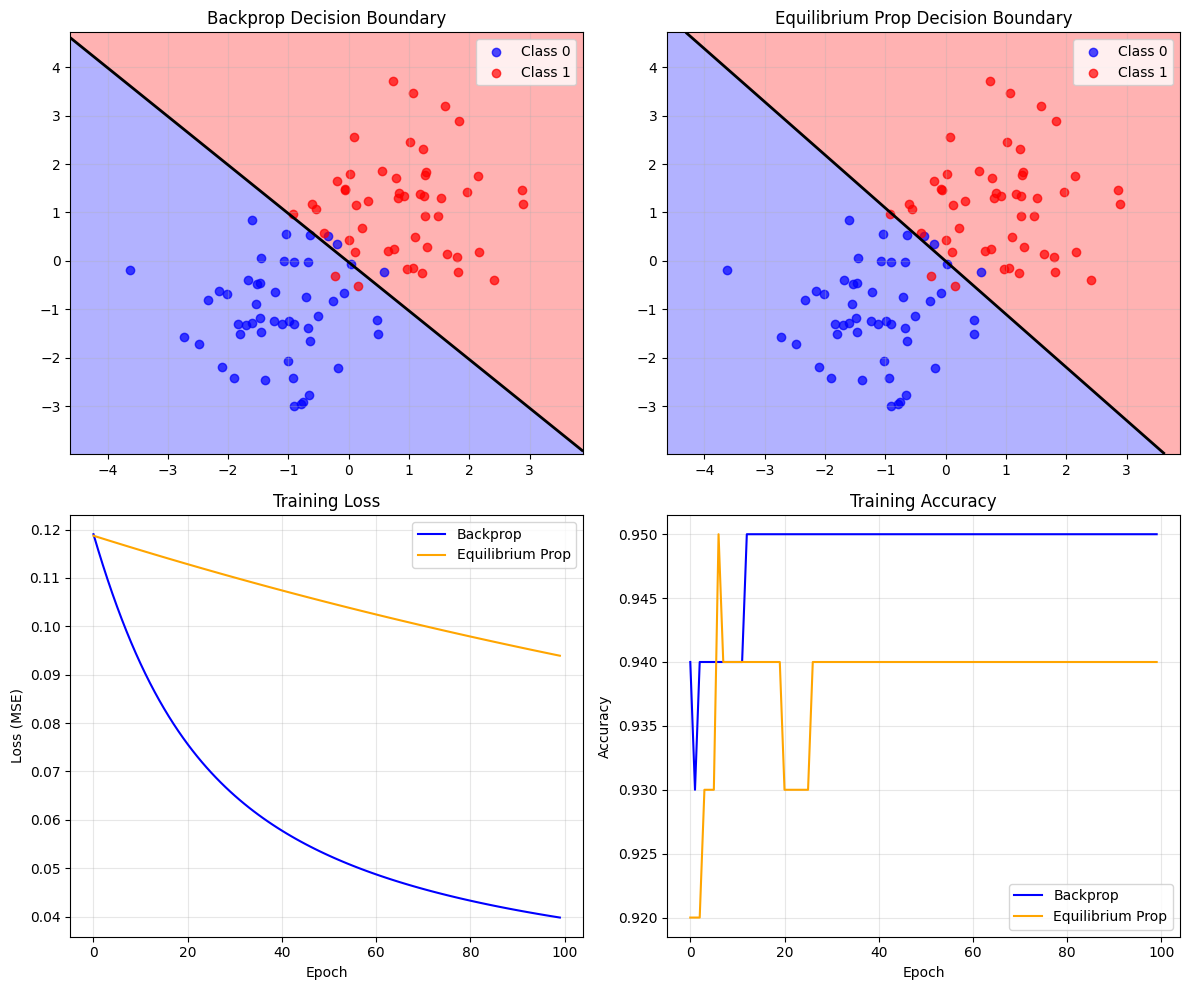

In [49]:
plot_full_comparison(
    results['X'], results['y'],
    results['model_bp'], results['model_ep'],
    results['history_bp'], results['history_ep']
)

(<Figure size 1400x400 with 3 Axes>,
 array([<Axes: title={'center': 'Weight 1 Evolution'}, xlabel='Epoch', ylabel='w1'>,
        <Axes: title={'center': 'Weight 2 Evolution'}, xlabel='Epoch', ylabel='w2'>,
        <Axes: title={'center': 'Bias Evolution'}, xlabel='Epoch', ylabel='b'>],
       dtype=object))

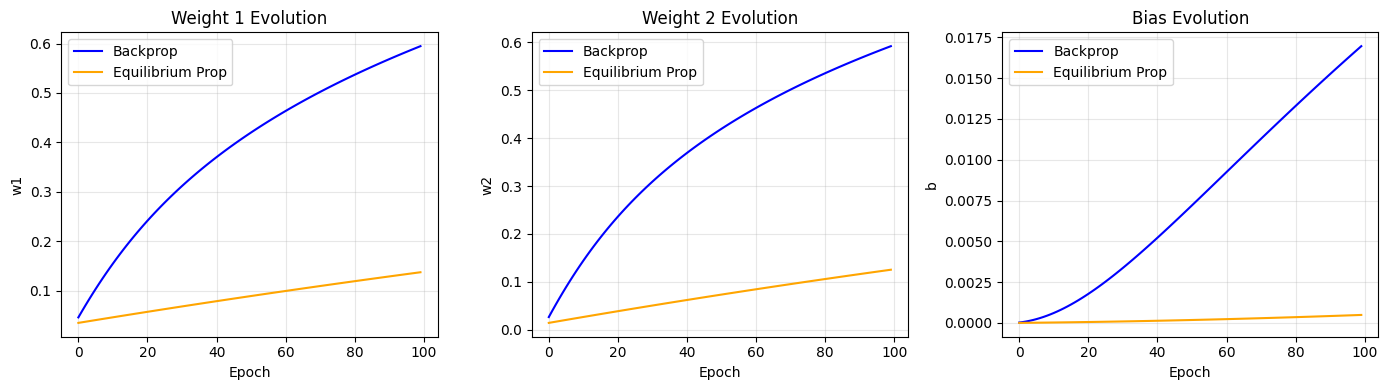

In [50]:
plot_weight_evolution(results['history_bp'], results['history_ep'])

<Axes: title={'center': 'Equilibrium Prop'}>

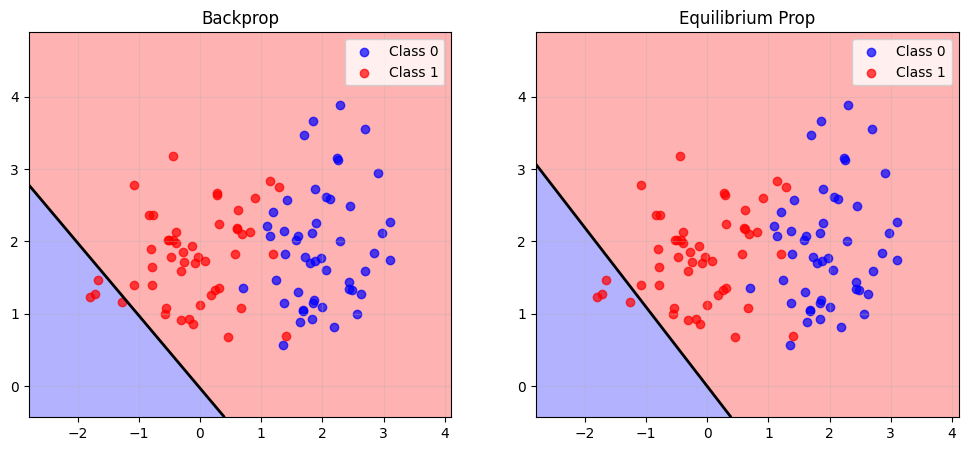

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_decision_boundary(results['model_bp'], X, y, ax=axes[0], title='Backprop')
plot_decision_boundary(results['model_ep'], X, y, ax=axes[1], title='Equilibrium Prop')

In [52]:
model = SimplePerceptron(seed=123)
history = train_backprop(model, torch.Tensor(X), torch.Tensor(y), num_epochs=50, lr=0.2, verbose=True, log_every=5)

BP Epoch 0: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 5: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 10: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 15: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 20: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 25: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 30: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 35: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 40: Loss = 0.1250, Accuracy = 50.00%
BP Epoch 45: Loss = 0.1250, Accuracy = 50.00%


/tmp/ipykernel_4327/940226409.py:151: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X)
/tmp/ipykernel_4327/940226409.py:153: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y)


In [53]:
print("Losses:", results['history_bp']['losses'][:10])
print("Final weights:", results['model_bp'].get_weights())

Losses: [0.11903409659862518, 0.11577099561691284, 0.11264698207378387, 0.10965970158576965, 0.10680608451366425, 0.10408242046833038, 0.10148449242115021, 0.0990077331662178, 0.09664729982614517, 0.09439826011657715]
Final weights: {'w': array([0.59463096, 0.59207773], dtype=float32), 'b': array([0.01695939], dtype=float32)}
